# **Machine Learning Course 2026 HW3: LLM Fast Inference**

- **Useful Links**
  - [ML 2026 Spring Course Website](https://speech.ee.ntu.edu.tw/~hylee/ml/2026-spring.php)
  - [NTU Cool HW3 作業討論區](https://cool.ntu.edu.tw/courses/59878/discussion_topics/482676)
  - [Homework Slide](https://docs.google.com/presentation/d/1DC8aUFTQIqwxxuLkl_RU-Wlny8q_Vfn9fUB_Hc_fvQw/edit?usp=sharing)

- **Notes**
  - Make a copy before running or editing the code.
  - Delete and create a new session when you start working on a new topic.

- **Questions for Included Topics**
  - Q11 ~ Q15: Speculative Decoding
  - Q16 ~ Q17: FlashAttention
  - Q18 ~ Q20: VLLM

In [ ]:
# check GPU
!nvidia-smi

Mon Mar 16 13:54:33 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## **Speculative Decoding**

### **Initialization (TODO)**

If you don't know how to create a huggingface token, please refer to:
- [Slide](https://speech.ee.ntu.edu.tw/~hylee/ml/ml2025-course-data/hw6_model.pdf)
- [Video](https://youtu.be/b8fad34gpFY)

In [ ]:
!hf auth login --token "" # TODO: Add your huggingface token

A new version of huggingface_hub (1.7.1) is available! You are using version 1.6.0.
To update, run: pip install -U huggingface_hub

The token has not been saved to the git credentials helper. Pass `add_to_git_credential=True` in this function directly or `--add-to-git-credential` if using via `hf`CLI if you want to set the git credential as well.
Token is valid (permission: read).
The token `vllm` has been saved to /root/.cache/huggingface/stored_tokens
Your token has been saved to /root/.cache/huggingface/token
Login successful.
The current active token is: `vllm`


In [ ]:
import os
import time
import random
import torch
import numpy as np
import matplotlib.pyplot as plt
import logging
from torch.nn import functional as F
from transformers import AutoTokenizer, AutoModelForCausalLM

torch.use_deterministic_algorithms(True)
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
logging.disable(logging.WARNING)

def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(1234)

# Detailed runtime diagnostics to explain why CUDA may be unavailable.
print(f"torch version: {torch.__version__}")
print(f"torch cuda build: {torch.version.cuda}")
print(f"cuda available: {torch.cuda.is_available()}")
print(f"cuda device count: {torch.cuda.device_count()}")

if torch.cuda.is_available():
    print(f"cuda device 0: {torch.cuda.get_device_name(0)}")
    device = "cuda"
else:
    device = "cpu"
    print("CUDA is unavailable in this runtime. Common causes: CPU-only torch wheel, missing/incompatible NVIDIA driver, or container not exposing GPU devices.")

print(f"Using device: {device}")

target_id = "google/gemma-3-1b-it"
assistant_id = "google/gemma-3-270m-it"

target_tokenizer = AutoTokenizer.from_pretrained(target_id)
assistant_tokenizer = AutoTokenizer.from_pretrained(assistant_id)

target_vocab = target_tokenizer.get_vocab()
assistant_vocab = assistant_tokenizer.get_vocab()

if target_vocab != assistant_vocab:
    raise ValueError(
        "Tokenizer/vocab mismatch between target and assistant models. "
        "Use models that share exactly the same tokenizer vocabulary."
    )

tokenizer = target_tokenizer

if tokenizer.pad_token_id is None and tokenizer.eos_token_id is not None:
    tokenizer.pad_token = tokenizer.eos_token

print(f"Tokenizer check passed. Shared vocab size: {len(target_vocab)}")

model_kwargs = {
    "dtype": torch.bfloat16,
    "device_map": "auto",
    "low_cpu_mem_usage": True,
    "attn_implementation": "eager",
}

target_model = AutoModelForCausalLM.from_pretrained(target_id, **model_kwargs)
assistant_model = AutoModelForCausalLM.from_pretrained(assistant_id, **model_kwargs,)

if not torch.cuda.is_available():
    target_model.to(device)
    assistant_model.to(device)

if torch.cuda.is_available():
    allocated_gb = torch.cuda.memory_allocated() / (1024 ** 3)
    reserved_gb = torch.cuda.memory_reserved() / (1024 ** 3)
    print(f"GPU memory allocated after load: {allocated_gb:.2f} GiB")
    print(f"GPU memory reserved after load: {reserved_gb:.2f} GiB")
    if reserved_gb > 15:
        print("Warning: GPU reserved memory is above 15 GiB. Consider CPU offload or a smaller target model.")

torch version: 2.10.0+cu128
torch cuda build: 12.8
cuda available: True
cuda device count: 1
cuda device 0: Tesla T4
Using device: cuda


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/899 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/33.4M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

... (11 outputs left out)

model.safetensors:   0%|          | 0.00/536M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/236 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

GPU memory allocated after load: 2.36 GiB
GPU memory reserved after load: 2.37 GiB


### **Manual Speculative Decoding (TODO)**

Goal: complete core speculative-decoding logic from [Accelerating Large Language Model Decoding with Speculative Sampling](https://arxiv.org/abs/2302.01318) paper.

- Implementation roadmap (follow in order):
  1. Draft `gamma` tokens from assistant logits.
  2. Run one target forward pass on drafted sequence.
  3. Compute acceptance ratio for each drafted token.
  4. If rejected, sample correction token from the corrected distribution.
  5. Track acceptance statistics and compute `alpha = accepted / drafted`.

- Notes
  - `assistant_model` is draft model in the paper.
  - Compared to the paper, definition of `q()` and `p()` are reversed:
    - `q()`: distribution from `assistant_model`
    - `p()`: distribution from `target_model`

In [ ]:
@torch.no_grad()
def manual_speculative_step_causal(
    target_model,
    assistant_model,
    input_ids,
    attention_mask=None,
    gamma=4,
    do_sample=False,
    temperature=1.0,
    eps=1e-9,
    step_idx=0,
):
    # ===== Initialize drafted sequence and bookkeeping =====
    step_seed = 1234 + step_idx
    # Clone the current context tokens into a draft buffer.
    draft_ids = input_ids.clone()
    # Create/clone an attention mask for the draft sequence.
    draft_attn = attention_mask.clone() if attention_mask is not None else torch.ones_like(input_ids)
    # Store assistant probabilities q(x) for each drafted token.
    draft_token_probs = []

    # ===== Assistant drafts gamma tokens =====
    for i in range(gamma):
        torch.manual_seed(step_seed + i)
        # Run assistant forward pass on current drafted context.
        a_out = assistant_model(
            input_ids=draft_ids,
            attention_mask=draft_attn,
            use_cache=False,
        )
        # Convert final-position logits to probabilities (temperature-scaled).
        logits = a_out.logits[:, -1, :] / max(temperature, eps)
        probs = F.softmax(logits, dim=-1)

        # Pick drafted token (sample if do_sample else greedy argmax).
        if do_sample:
            next_token = torch.multinomial(probs, num_samples=1)
        else:
            next_token = torch.argmax(probs, dim=-1, keepdim=True)

        # Record q(x) for the drafted token and append token to context.
        q_x = probs.gather(-1, next_token).squeeze(-1)
        draft_token_probs.append(q_x)
        draft_ids = torch.cat([draft_ids, next_token], dim=-1)
        draft_attn = torch.cat([draft_attn, torch.ones_like(next_token)], dim=-1)

    # ===== Verify drafted positions with one target pass =====
    t_out = target_model(
        input_ids=draft_ids,
        attention_mask=draft_attn,
        use_cache=False,
    )
    t_probs = F.softmax(t_out.logits, dim=-1)

    accepted = 0
    new_ids = input_ids.clone()
    new_attn = attention_mask.clone() if attention_mask is not None else torch.ones_like(input_ids)
    prefix_len = input_ids.shape[1]

    # ===== Acceptance/Rejection loop for each drafted token =====
    for i in range(gamma):
        token = draft_ids[:, prefix_len + i : prefix_len + i + 1]
        p_i = t_probs[:, prefix_len - 1 + i, :]
        p_x = p_i.gather(-1, token).squeeze(-1)
        q_x = draft_token_probs[i]

        # Compute accept ratio min(1, p(x)/q(x)) and sample Bernoulli accept.
        ratio = torch.clamp(p_x / (q_x + eps), max=1.0)
        accept = torch.rand_like(ratio) < ratio

        if bool(accept.item()):
            # Append accepted drafted token.
            accepted += 1
            new_ids = torch.cat([new_ids, token], dim=-1)
            new_attn = torch.cat([new_attn, torch.ones_like(token)], dim=-1)
        else:
            # ===== Correction token from p' = normalize(max(p - q, 0)) =====
            torch.manual_seed(step_seed + i + 999)
            a_prefix_ids = draft_ids[:, : prefix_len + i]
            a_prefix_attn = draft_attn[:, : prefix_len + i]
            a_prefix = assistant_model(
                input_ids=a_prefix_ids,
                attention_mask=a_prefix_attn,
                use_cache=False,
            )
            q_full = F.softmax(a_prefix.logits[:, -1, :] / max(temperature, eps), dim=-1)

            # TODO: calculate the difference of distribution of prob between p(x) and q(x)
            diff =
            denom = diff.sum(dim=-1, keepdim=True)
            fallback = torch.argmax(p_i, dim=-1, keepdim=True)

            # If normalization is degenerate, use fallback argmax from target.
            if bool((denom <= eps).item()):
                correction = fallback
            else:
                # Sample correction token from normalized diff distribution.
                p_prime = diff / denom
                correction = torch.multinomial(p_prime, num_samples=1)

            new_ids = torch.cat([new_ids, correction], dim=-1)
            new_attn = torch.cat([new_attn, torch.ones_like(correction)], dim=-1)
            return new_ids, new_attn, accepted

    # ===== Bonus token when all gamma drafts are accepted =====
    bonus_dist = t_probs[:, -1, :]
    if do_sample:
        bonus = torch.multinomial(bonus_dist, num_samples=1)
    else:
        bonus = torch.argmax(bonus_dist, dim=-1, keepdim=True)
    new_ids = torch.cat([new_ids, bonus], dim=-1)
    new_attn = torch.cat([new_attn, torch.ones_like(bonus)], dim=-1)

    return new_ids, new_attn, accepted

@torch.no_grad()
def speculative_generate_manual_seq2seq(
    target_model,
    assistant_model,
    encoder_inputs,
    tokenizer,
    max_new_tokens=128,
    gamma=4,
    eos_token_id=None,
    do_sample=False,
    temperature=1.0,
):
    # Kept function name for notebook continuity; implementation is for decoder-only Gemma models.
    if getattr(target_model.config, "is_encoder_decoder", False):
        raise ValueError("This manual implementation is configured for decoder-only Gemma models.")

    if eos_token_id is None:
        eos_token_id = tokenizer.eos_token_id

    # ===== Initialize generation state =====
    generated_ids = encoder_inputs["input_ids"].clone()
    generated_attn = encoder_inputs.get("attention_mask", torch.ones_like(generated_ids)).clone()
    prompt_len = generated_ids.shape[1]

    total_accepted = 0
    total_drafted = 0

    # ===== Iterate until max_new_tokens or EOS =====
    step_count = 0
    while generated_ids.shape[1] - prompt_len < max_new_tokens:
        generated_ids, generated_attn, accepted = manual_speculative_step_causal(
            target_model=target_model,
            assistant_model=assistant_model,
            input_ids=generated_ids,
            attention_mask=generated_attn,
            gamma=gamma,
            do_sample=do_sample,
            temperature=temperature,
            step_idx=step_count,
        )
        step_count += 1
        total_accepted += accepted
        total_drafted += gamma

        if eos_token_id is not None and (generated_ids[:, prompt_len:] == eos_token_id).any():
            break
        if generated_ids.shape[1] - prompt_len >= max_new_tokens:
            break

    # ===== Compute acceptance-rate statistic alpha =====
    alpha = total_accepted / total_drafted if total_drafted > 0 else 0.0
    return generated_ids, alpha

In [ ]:
source_text = """
Fast Inference from Transformers via Speculative Decoding studies how to reduce generation latency
in large language models. Transformer decoding is autoregressive, so each next token depends on prior
tokens. This serial process under-utilizes compute because memory movement, not arithmetic throughput,
is often the bottleneck.

The core idea is to use a small draft model to propose several tokens, then verify them with a larger
target model in fewer expensive passes. If draft proposals match target preferences, multiple tokens can
be accepted at once. If not, the target model corrects and generation continues. The method can preserve
the target distribution with rejection-sampling style corrections while reducing wall-clock latency.

Empirical results show speedups across tasks like summarization and dialogue, but the gain depends on
draft quality, lookahead length (gamma), and hardware bottlenecks. Very large gamma can introduce waste
if many draft tokens are rejected or if orchestration overhead dominates.
"""

# Normal prompt
prompt = f"""<start_of_turn>user
Summarize and expand the following content. First give a concise summary in 5 bullets, then provide a deeper explanation with practical implications for inference systems.

{source_text}<end_of_turn>
<start_of_turn>model
"""

# TODO: try this simple prompt to test alpha in a simpler task
# prompt = f"""<start_of_turn>user
# You are a helpful AI assistant.

# Repeat the following content:

# {source_text}<end_of_turn>
# <start_of_turn>model
# """

inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=2048)
inputs = {k: v.to(device) for k, v in inputs.items()}
print(f"Prompt tokens: {inputs['input_ids'].shape[1]}")

Prompt tokens: 230


In [ ]:
# Quick manual-speculative smoke test (small token budget for class demos).
start = time.time()
manual_ids, manual_alpha = speculative_generate_manual_seq2seq(
    target_model=target_model,
    assistant_model=assistant_model,
    encoder_inputs=inputs,
    tokenizer=tokenizer,
    max_new_tokens=64,
    gamma=6, # You can try different gamma and observe run time and alpha
    eos_token_id=tokenizer.eos_token_id,
    do_sample=False,
)

prompt_len = inputs["input_ids"].shape[1]
manual_text = tokenizer.decode(manual_ids[0, :], skip_special_tokens=False)
print(f"Run time: {(time.time() - start):.4f}s")
print(f"Manual speculative alpha: {manual_alpha:.4f}")
print("Manual speculative output preview:")
print(manual_text)

Run time: 21.6088s
Manual speculative alpha: 0.3750
Manual speculative output preview:
<bos><start_of_turn>user
Summarize and expand the following content. First give a concise summary in 5 bullets, then provide a deeper explanation with practical implications for inference systems.


Fast Inference from Transformers via Speculative Decoding studies how to reduce generation latency
in large language models. Transformer decoding is autoregressive, so each next token depends on prior
tokens. This serial process under-utilizes compute because memory movement, not arithmetic throughput,
is often the bottleneck.

The core idea is to use a small draft model to propose several tokens, then verify them with a larger
target model in fewer expensive passes. If draft proposals match target preferences, multiple tokens can
be accepted at once. If not, the target model corrects and generation continues. The method can preserve
the target distribution with rejection-sampling style corrections while 

### **Benchmark with Two Prompt Regimes**

In this part, you will compare speculative decoding behavior under two utilization situations:
1. **Low-utilization case**: short/simple prompt and short output budget.
2. **High-utilization case**: long/complex prompt and longer output budget.

Experiment protocol:
1. Run the next benchmark cell once; it evaluates both cases automatically.
2. Compare speedup curves (`assistant` and `n-gram`) between the two cases.
3. Explain differences using acceptance quality, overhead, and workload size.

In [ ]:
def timed_generate(call_fn):
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t0 = time.time()
    _ = call_fn()
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return time.time() - t0

def run_speed_benchmark_for_prompt(prompt_text, max_new_tokens, gamma_values):
    bench_inputs = tokenizer(prompt_text, return_tensors="pt", truncation=True, max_length=2048)
    bench_inputs = {k: v.to(device) for k, v in bench_inputs.items()}

    # Warmup for fair timing.
    _ = target_model.generate(**bench_inputs, max_new_tokens=8, do_sample=False)

    baseline_time = timed_generate(
        lambda: target_model.generate(
            **bench_inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id,
        )
    )

    speedups_assistant = []
    speedups_ngram = []
    assistant_errors = {}
    ngram_errors = {}

    for g in gamma_values:
        try:
            t_assist = timed_generate(
                lambda: target_model.generate(
                    **bench_inputs,
                    assistant_model=assistant_model,
                    num_assistant_tokens=g,
                    max_new_tokens=max_new_tokens,
                    do_sample=False,
                    pad_token_id=tokenizer.pad_token_id,
                )
            )
            speedups_assistant.append(baseline_time / t_assist if t_assist > 0 else np.nan)
        except Exception as e:
            speedups_assistant.append(np.nan)
            assistant_errors[g] = str(e)

        try:
            t_ngram = timed_generate(
                lambda: target_model.generate(
                    **bench_inputs,
                    prompt_lookup_num_tokens=g,
                    max_new_tokens=max_new_tokens,
                    do_sample=False,
                    pad_token_id=tokenizer.pad_token_id,
                )
            )
            speedups_ngram.append(baseline_time / t_ngram if t_ngram > 0 else np.nan)
        except Exception as e:
            speedups_ngram.append(np.nan)
            ngram_errors[g] = str(e)

    return {
        "baseline_time": baseline_time,
        "speedups_assistant": speedups_assistant,
        "speedups_ngram": speedups_ngram,
        "assistant_errors": assistant_errors,
        "ngram_errors": ngram_errors,
        "prompt_tokens": int(bench_inputs["input_ids"].shape[1]),
        "max_new_tokens": int(max_new_tokens),
    }

low_util_prompt = f"""<start_of_turn>user
Count from 1 to 20.<end_of_turn>
<start_of_turn>model
"""
high_util_prompt = f"""<start_of_turn>user
Seperate the following article into sentences. One sentence per line.

{source_text}<end_of_turn>
<start_of_turn>model
"""

prompt_cases = {
    "low_util_short": {"prompt": low_util_prompt, "max_new_tokens": 64},
    "high_util_long": {"prompt": high_util_prompt, "max_new_tokens": 128},
}

gamma_values = list(range(1, 11))
results_by_case = {}

for case_name, cfg in prompt_cases.items():
    print(f"\n=== Running case: {case_name} ===")
    res = run_speed_benchmark_for_prompt(
        prompt_text=cfg["prompt"],
        max_new_tokens=cfg["max_new_tokens"],
        gamma_values=gamma_values,
    )
    results_by_case[case_name] = res

    print(
        f"Prompt tokens: {res['prompt_tokens']} | "
        f"max_new_tokens: {res['max_new_tokens']} | "
        f"baseline: {res['baseline_time']:.3f}s"
    )
    for i, g in enumerate(gamma_values):
        a = res["speedups_assistant"][i]
        n = res["speedups_ngram"][i]
        print(f"gamma={g:2d} | gemma-270m={a:.3f}x | ngram={n:.3f}x")

    if res["assistant_errors"]:
        print("Assistant mode errors by gamma:")
        for g, msg in res["assistant_errors"].items():
            print(f"  gamma={g}: {msg}")

    if res["ngram_errors"]:
        print("N-gram mode errors by gamma:")
        for g, msg in res["ngram_errors"].items():
            print(f"  gamma={g}: {msg}")


=== Running case: low_util_short ===
Prompt tokens: 18 | max_new_tokens: 64 | baseline: 5.947s
gamma= 1 | gemma-270m=1.169x | ngram=1.364x
gamma= 2 | gemma-270m=1.408x | ngram=1.296x
gamma= 3 | gemma-270m=1.398x | ngram=1.524x
gamma= 4 | gemma-270m=1.165x | ngram=1.540x
gamma= 5 | gemma-270m=1.326x | ngram=1.352x
gamma= 6 | gemma-270m=1.391x | ngram=1.446x
gamma= 7 | gemma-270m=1.251x | ngram=1.559x
gamma= 8 | gemma-270m=1.187x | ngram=1.526x
gamma= 9 | gemma-270m=1.401x | ngram=1.302x
gamma=10 | gemma-270m=1.391x | ngram=1.518x

=== Running case: high_util_long ===
Prompt tokens: 213 | max_new_tokens: 128 | baseline: 11.631s
gamma= 1 | gemma-270m=0.772x | ngram=1.320x
gamma= 2 | gemma-270m=0.798x | ngram=1.455x
gamma= 3 | gemma-270m=0.803x | ngram=1.555x
gamma= 4 | gemma-270m=0.786x | ngram=1.715x
gamma= 5 | gemma-270m=0.782x | ngram=1.900x
gamma= 6 | gemma-270m=0.775x | ngram=1.782x
gamma= 7 | gemma-270m=0.789x | ngram=1.792x
gamma= 8 | gemma-270m=0.797x | ngram=1.990x
gamma= 9 | ge

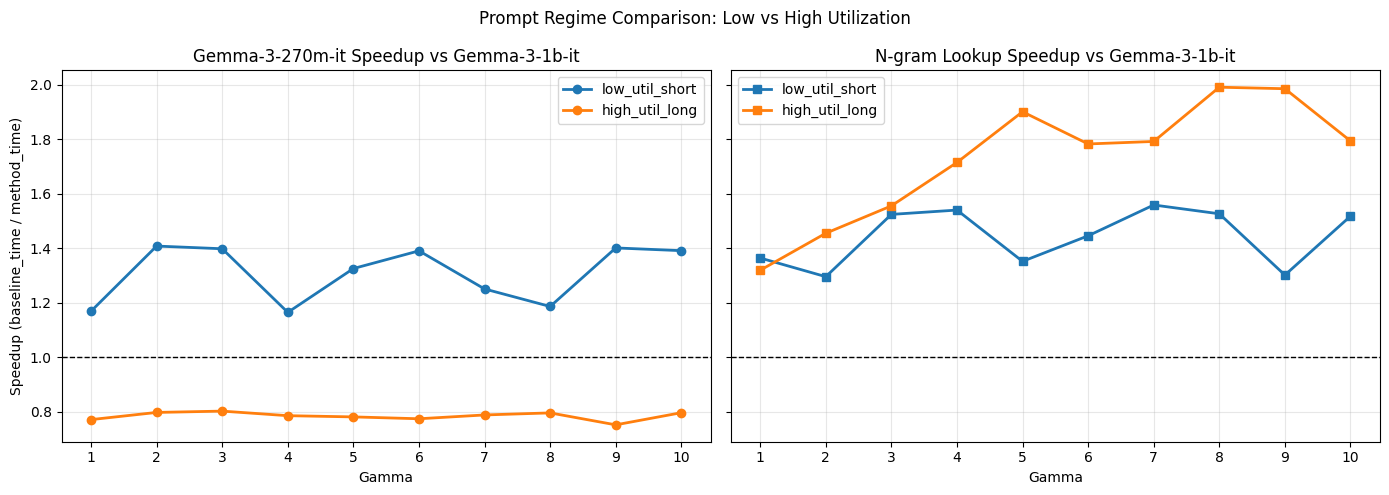

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for case_name, res in results_by_case.items():
    axes[0].plot(
        gamma_values,
        res["speedups_assistant"],
        marker="o",
        linewidth=2,
        label=case_name,
    )
    axes[1].plot(
        gamma_values,
        res["speedups_ngram"],
        marker="s",
        linewidth=2,
        label=case_name,
    )

for ax in axes:
    ax.axhline(1.0, color="black", linestyle="--", linewidth=1)
    ax.set_xticks(gamma_values)
    ax.grid(alpha=0.3)
    ax.set_xlabel("Gamma")
    ax.legend()

axes[0].set_title("Gemma-3-270m-it Speedup vs Gemma-3-1b-it")
axes[1].set_title("N-gram Lookup Speedup vs Gemma-3-1b-it")
axes[0].set_ylabel("Speedup (baseline_time / method_time)")
plt.suptitle("Prompt Regime Comparison: Low vs High Utilization")
plt.tight_layout()
plt.show()

## **FlashAttention**

Benchmark **Standard Attention** and **FlashAttention** algorithms from the paper [FlashAttention: Fast and Memory-Efficient Exact Attention with IO-Awareness](https://arxiv.org/abs/2205.14135).
- For both algorithms, detailed operations in attention calculation, such as `mask` and `dropout`, are skipped.
- The following algorithm implemented in Python does not provide actual acceleration. In practice, FlashAttention achieves real speedups by using lower-level programming languages such as CUDA or C++.




### **Initialization**

In [ ]:
import json
import math
import torch
import matplotlib.pyplot as plt
from typing import Dict, Tuple

N = 1024 # sequence length
d = 64 # head dimension

Q_hbm = torch.randn(N, d, device="cuda")
K_hbm = torch.randn(N, d, device="cuda")
V_hbm = torch.randn(N, d, device="cuda")

print(Q_hbm)
print(K_hbm)
print(V_hbm)

tensor([[-0.9508, -1.0015, -0.2156,  ...,  0.9050,  2.1047, -1.8999],
        [-0.2792, -0.2440,  0.2341,  ...,  1.1138,  0.7183,  0.5226],
        [-1.0197, -1.7182, -0.4925,  ...,  0.7325, -0.6404, -0.6073],
        ...,
        [-0.0157,  1.3173,  0.5215,  ...,  0.0627, -0.2157,  1.7727],
        [-0.5048, -0.5450,  0.9014,  ...,  0.3725,  1.1551,  0.6991],
        [-0.1234, -1.7342,  0.2024,  ...,  2.3847, -0.7486,  1.5957]],
       device='cuda:0')
tensor([[ 0.2716, -0.3774,  0.4820,  ...,  1.0924, -1.2178,  1.5725],
        [ 0.5023,  0.7374, -0.8450,  ..., -1.4736,  0.3549,  0.2904],
        [-2.4399,  0.8370,  0.2777,  ...,  0.2213, -0.0120, -0.1697],
        ...,
        [ 0.0455, -0.2279, -2.0946,  ..., -1.4863, -0.0275, -0.2006],
        [ 0.7747, -1.0799,  0.3094,  ..., -1.2442,  0.3912, -0.3388],
        [-0.3664, -1.4512,  2.1008,  ..., -0.2039, -1.2313, -2.3897]],
       device='cuda:0')
tensor([[-3.8567e-01, -3.3485e-01, -3.7520e+00,  ...,  6.7919e-01,
         -3.4831e

### **Standard Attention**

In [ ]:
def standard_attention_with_io_count(
    Q_hbm: torch.Tensor,
    K_hbm: torch.Tensor,
    V_hbm: torch.Tensor,
) -> Tuple[torch.Tensor, Dict[str, int]]:

    N, d = Q_hbm.shape

    stats = {
        "hbm_read_floats": 0,
        "hbm_write_floats": 0,
        "total_memory_floats": 0,
        "flops": 0,
    }

    # --------------------------------------------------
    # Step 1:
    # Load Q, K from HBM -> SRAM
    # Compute S = QK^T
    # Write S to HBM
    # --------------------------------------------------
    Q_sram = Q_hbm
    K_sram = K_hbm
    stats["hbm_read_floats"] += Q_hbm.numel() + K_hbm.numel()

    S_sram = Q_sram @ K_sram.T
    stats["flops"] += N * N * (2 * d - 1)

    S_hbm = S_sram
    stats["hbm_write_floats"] += S_hbm.numel()

    # --------------------------------------------------
    # Step 2:
    # Read S from HBM -> SRAM
    # Compute P = softmax(S)
    # Write P to HBM
    # --------------------------------------------------
    S_sram = S_hbm
    stats["hbm_read_floats"] += S_hbm.numel()

    P_sram = torch.softmax(S_sram, dim=-1)

    # Approximate softmax FLOPs:
    # 5 FLOPs per element: exp(1) + add/sub/max/div
    stats["flops"] += 5 * N * N

    P_hbm = P_sram
    stats["hbm_write_floats"] += P_hbm.numel()

    # --------------------------------------------------
    # Step 3:
    # Load P, V from HBM -> SRAM
    # Compute O = PV
    # Write O to HBM
    # --------------------------------------------------
    P_sram = P_hbm
    V_sram = V_hbm
    stats["hbm_read_floats"] += P_hbm.numel() + V_hbm.numel()

    O_sram = P_sram @ V_sram
    stats["flops"] += N * d * (2 * N - 1)

    O_hbm = O_sram
    stats["hbm_write_floats"] += O_hbm.numel()

    stats["total_memory_floats"] = (
        stats["hbm_read_floats"] + stats["hbm_write_floats"]
    )

    return O_hbm, stats

In [ ]:
O_hbm, stats = standard_attention_with_io_count(Q_hbm, K_hbm, V_hbm)
print(O_hbm)
print("O_hbm.shape =", O_hbm.shape)
print(json.dumps(stats, indent=4))

tensor([[-0.7908,  0.1587, -0.2246,  ..., -0.2513,  0.5339,  0.7535],
        [ 0.7095,  1.2101, -0.4734,  ..., -0.0079,  0.4364,  0.1146],
        [-0.6746,  0.1466, -0.0602,  ...,  0.8163, -0.4238, -0.1035],
        ...,
        [-0.3181,  0.3562,  0.5632,  ..., -0.0936,  0.3723,  0.3703],
        [ 0.5980, -1.2516,  0.9692,  ..., -1.0940, -0.0139, -0.6012],
        [ 0.6356, -0.2146, -1.5098,  ..., -1.2882, -0.8461,  1.7371]],
       device='cuda:0')
O_hbm.shape = torch.Size([1024, 64])
{
    "hbm_read_floats": 2293760,
    "hbm_write_floats": 2162688,
    "total_memory_floats": 4456448,
    "flops": 272564224
}


### **FlashAttention**

In [ ]:
def flash_attention_with_io_count(
    Q_hbm: torch.Tensor,
    K_hbm: torch.Tensor,
    V_hbm: torch.Tensor,
    M: int = 64000, # 64 KB on chip SRAM for T4
) -> Tuple[torch.Tensor, Dict[str, int]]:

    N, d = Q_hbm.shape

    stats = {
        "hbm_read_floats": 0,
        "hbm_write_floats": 0,
        "total_memory_floats": 0,
        "flops": 0,
    }

    # --------------------------------------------------
    # FlashAttention paper-style block sizes
    #
    # A common simplified derivation used in teaching is:
    #   Bc = floor(M / (4d))
    #   Br = min(Bc, d)
    #
    # so that the SRAM can hold:
    #   K_j, V_j, Q_i, O_i, and small aux vectors/statistics.
    # --------------------------------------------------
    Bc = max(1, M // (4 * d))
    Br = max(1, min(Bc, d))

    # --------------------------------------------------
    # Initialize O, l, m in HBM
    #
    # O: running output
    # l: running denominator of softmax
    # m: running row-wise max for numerical stability
    # --------------------------------------------------
    O_hbm = torch.zeros_like(Q_hbm)
    l_hbm = torch.zeros(N, device=Q_hbm.device, dtype=Q_hbm.dtype)
    m_hbm = torch.full(
        (N,),
        -torch.inf,
        device=Q_hbm.device,
        dtype=Q_hbm.dtype,
    )

    stats["hbm_write_floats"] += O_hbm.numel() + l_hbm.numel() + m_hbm.numel()

    # --------------------------------------------------
    # Outer loop over K/V column blocks
    # --------------------------------------------------
    for j_start in range(0, N, Bc):
        j_end = min(j_start + Bc, N)
        bc = j_end - j_start

        # Load K_j, V_j from HBM -> SRAM
        K_j_sram = K_hbm[j_start:j_end]
        V_j_sram = V_hbm[j_start:j_end]
        stats["hbm_read_floats"] += K_j_sram.numel() + V_j_sram.numel()

        # --------------------------------------------------
        # Inner loop over Q/O/l/m row blocks
        # --------------------------------------------------
        for i_start in range(0, N, Br):
            i_end = min(i_start + Br, N)
            br = i_end - i_start

            # Load Q_i, O_i, l_i, m_i from HBM -> SRAM
            Q_i_sram = Q_hbm[i_start:i_end]
            O_i_sram = O_hbm[i_start:i_end]
            l_i_sram = l_hbm[i_start:i_end]
            m_i_sram = m_hbm[i_start:i_end]

            stats["hbm_read_floats"] += (
                Q_i_sram.numel()
                + O_i_sram.numel()
                + l_i_sram.numel()
                + m_i_sram.numel()
            )

            # ----------------------------------------------
            # Step 1:
            # S_ij = Q_i K_j^T
            # ----------------------------------------------
            S_ij_sram = Q_i_sram @ K_j_sram.T
            stats["flops"] += br * bc * (2 * d - 1)

            # ----------------------------------------------
            # Step 2:
            # Online softmax bookkeeping
            #
            # m_ij = rowmax(S_ij)
            # p_ij = exp(S_ij - m_ij)
            # l_ij = rowsum(p_ij)
            #
            # m_new = max(m_i, m_ij)
            # l_new = exp(m_i - m_new) * l_i + exp(m_ij - m_new) * l_ij
            # O_new = (
            #   exp(m_i - m_new) * l_i * O_i
            #   + exp(m_ij - m_new) * (p_ij @ V_j)
            # ) / l_new
            # ----------------------------------------------
            m_ij_sram = torch.max(S_ij_sram, dim=1).values
            stats["flops"] += br * max(bc - 1, 0)

            P_ij_sram = torch.exp(S_ij_sram - m_ij_sram[:, None])
            # subtract + exp
            stats["flops"] += 2 * br * bc

            l_ij_sram = torch.sum(P_ij_sram, dim=1)
            stats["flops"] += br * max(bc - 1, 0)

            m_new_sram = torch.maximum(m_i_sram, m_ij_sram)
            stats["flops"] += br

            alpha = torch.exp(m_i_sram - m_new_sram)
            beta = torch.exp(m_ij_sram - m_new_sram)
            # two subtract + two exp
            stats["flops"] += 4 * br

            l_new_sram = alpha * l_i_sram + beta * l_ij_sram
            stats["flops"] += 3 * br

            # ----------------------------------------------
            # Step 3:
            # Partial output for this tile
            # ----------------------------------------------
            PV_ij_sram = P_ij_sram @ V_j_sram
            stats["flops"] += br * d * (2 * bc - 1)

            # rescale old accumulator + combine + normalize
            O_i_sram = (
                alpha[:, None] * l_i_sram[:, None] * O_i_sram
                + beta[:, None] * PV_ij_sram
            ) / l_new_sram[:, None]

            # Approximate FLOPs for the accumulator update:
            #   alpha * l_i                  -> br
            #   (alpha*l_i) * O_i           -> br*d
            #   beta * PV                    -> br*d
            #   add                          -> br*d
            #   divide by l_new              -> br*d
            stats["flops"] += br + 4 * br * d

            # ----------------------------------------------
            # Write updated O_i, l_i, m_i back to HBM
            # ----------------------------------------------
            O_hbm[i_start:i_end] = O_i_sram
            l_hbm[i_start:i_end] = l_new_sram
            m_hbm[i_start:i_end] = m_new_sram

            stats["hbm_write_floats"] += (
                O_i_sram.numel() + l_new_sram.numel() + m_new_sram.numel()
            )

    stats["total_memory_floats"] = (
        stats["hbm_read_floats"] + stats["hbm_write_floats"]
    )

    return O_hbm, stats

In [ ]:
O_hbm, stats = flash_attention_with_io_count(Q_hbm, K_hbm, V_hbm)
print(O_hbm)
print("O_hbm.shape =", O_hbm.shape)
print(json.dumps(stats, indent=4))

tensor([[-0.7908,  0.1587, -0.2246,  ..., -0.2513,  0.5339,  0.7535],
        [ 0.7095,  1.2101, -0.4734,  ..., -0.0079,  0.4364,  0.1146],
        [-0.6746,  0.1466, -0.0602,  ...,  0.8163, -0.4238, -0.1035],
        ...,
        [-0.3181,  0.3562,  0.5632,  ..., -0.0936,  0.3723,  0.3703],
        [ 0.5980, -1.2516,  0.9692,  ..., -1.0940, -0.0139, -0.6012],
        [ 0.6356, -0.2146, -1.5098,  ..., -1.2882, -0.8461,  1.7371]],
       device='cuda:0')
O_hbm.shape = torch.Size([1024, 64])
{
    "hbm_read_floats": 796672,
    "hbm_write_floats": 405504,
    "total_memory_floats": 1202176,
    "flops": 272600064
}


### **Standard Attention vs. FlashAttention**

standard_gflops = [0.068124672, 0.272564224, 1.090387968, 4.361814016, 17.447780352]
flash_gflops = [0.06820096, 0.272600064, 1.089992704, 4.359155712, 17.43499264]
standard_hbm_rw_gb = [0.004718592, 0.017825792, 0.069206016, 0.27262976, 1.082130432]
flash_hbm_rw_gb = [0.001601536, 0.004808704, 0.016039936, 0.057769984, 0.218300416]


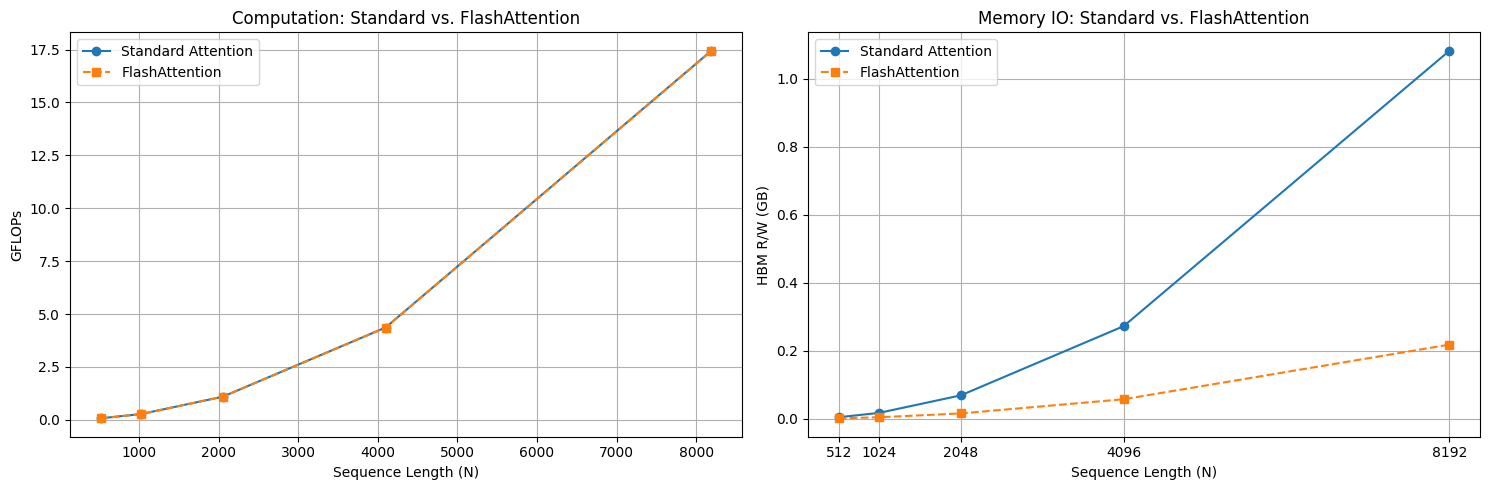

In [ ]:
Ns = [512, 1024, 2048, 4096, 8192]
d = 64

standard_gflops = []
flash_gflops = []

standard_hbm_rw_gb = []
flash_hbm_rw_gb = []

for N in Ns:
    Q_hbm = torch.randn(N, d, device="cuda")
    K_hbm = torch.randn(N, d, device="cuda")
    V_hbm = torch.randn(N, d, device="cuda")

    standard_O_hbm, standard_stats = standard_attention_with_io_count(Q_hbm, K_hbm, V_hbm)
    flash_O_hbm, flash_stats = flash_attention_with_io_count(Q_hbm, K_hbm, V_hbm)

    standard_gflops.append(standard_stats["flops"] / 1e9)
    flash_gflops.append(flash_stats["flops"] / 1e9)

    # Assuming 4 bytes per float (float32)
    standard_hbm_rw_gb.append((standard_stats["total_memory_floats"] * 4) / 1e9)
    flash_hbm_rw_gb.append((flash_stats["total_memory_floats"] * 4) / 1e9)

print("standard_gflops =", standard_gflops)
print("flash_gflops =", flash_gflops)

print("standard_hbm_rw_gb =", standard_hbm_rw_gb)
print("flash_hbm_rw_gb =", flash_hbm_rw_gb)

# Plotting
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
plt.xticks(Ns)

# GFLOPs Plot
ax1.plot(Ns, standard_gflops, 'o-', label="Standard Attention")
ax1.plot(Ns, flash_gflops, 's--', label="FlashAttention")
ax1.set_xlabel("Sequence Length (N)")
ax1.set_ylabel("GFLOPs")
ax1.set_title("Computation: Standard vs. FlashAttention")
ax1.legend()
ax1.grid(True)

# HBM R/W Plot
ax2.plot(Ns, standard_hbm_rw_gb, 'o-', label="Standard Attention")
ax2.plot(Ns, flash_hbm_rw_gb, 's--', label="FlashAttention")
ax2.set_xlabel("Sequence Length (N)")
ax2.set_ylabel("HBM R/W (GB)")
ax2.set_title("Memory IO: Standard vs. FlashAttention")
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

### **Run Time Calculation (TODO)**

T4 GPU
- Single Precision Performance (FP32): $8.1 TFLOPS$
- Memory Bandwidth: $320 GB/s$

In [ ]:
# TODO: modify the whole block to calculate speed up for different sequence lengths
# Simple run time calculation example
flops = 272600064
total_memory_floats = 1202176

run_time = flops / (8.1 * 1e12) + 4 * total_memory_floats / (320 * 1e9)
print(f"Run Time: {(run_time * 1e3):.4f}ms")

Run Time: 0.0487ms


## **VLLM**

### **Initialization (TODO)**

If you don't know how to create a huggingface token and access `meta-llama/Llama-3.2-3B-Instruct`, please refer to:
- [Slide](https://speech.ee.ntu.edu.tw/~hylee/ml/ml2025-course-data/hw6_model.pdf)
- [Video](https://youtu.be/b8fad34gpFY)

In [ ]:
# It might take a few minutes
!pip install vllm==0.6.3.post1 transformers==4.47.1 accelerate pandas

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 3.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 6.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
INFO: pip is looking at multiple versions of opencv-python-headless to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.8/194.8 MB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 77.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 92.0/92.0 kB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.6/71.6 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 797.2/797.2 MB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.0/7.0 MB 95.8 MB/s eta 0:0

In [ ]:
!hf auth login --token "" # TODO: Add your huggingface token

The token has not been saved to the git credentials helper. Pass `add_to_git_credential=True` in this function directly or `--add-to-git-credential` if using via `hf`CLI if you want to set the git credential as well.
Token is valid (permission: read).
The token `vllm` has been saved to /root/.cache/huggingface/stored_tokens
Your token has been saved to /root/.cache/huggingface/token
Login successful.
The current active token is: `vllm`


In [ ]:
!gdown 1PoblmXkhKRGN73Qgkc6NZX9SV0reY_dQ --output natural_massive_text.txt

Downloading...
From: https://drive.google.com/uc?id=1PoblmXkhKRGN73Qgkc6NZX9SV0reY_dQ
To: /content/natural_massive_text.txt
100% 105k/105k [00:00<00:00, 32.0MB/s]


### **KV Cache Multi-turn Test**

In [ ]:
%%writefile multi_turn_kv_test.py
import time
from vllm import LLM, SamplingParams

def run_document_only_experiment():
    print("\n" + "="*20 + " Document-Only Prefix Cache Test " + "="*20)

    with open("natural_massive_text.txt", "r") as f:
        document = f.read()

    model_id = "meta-llama/Llama-3.2-3B-Instruct"

    # Using exactly the same settings as your successful run
    llm = LLM(
        model=model_id,
        enable_prefix_caching=True  , # Set to false to see inference without kvcache.
        enforce_eager=True,
        max_model_len=32768,
        gpu_memory_utilization=0.95, # Set to 0.85 to be safe on T4
        dtype="float16",
        trust_remote_code=True
    )

    sampling_params = SamplingParams(
        temperature=0.0,
        max_tokens=128,
        stop=["<|eot_id|>"]
    )

    # REVERT to the working format: using <|begin_of_text|> and 'user' role
    # This ensures the Token IDs at the beginning match your 2.65x success
    shared_prefix = f"<|begin_of_text|><|start_header_id|>user<|end_header_id|>\n\nContext document: {document}\n\n"

    questions = [
        "What is the main topic of the first chapter?",
        "Shortly introduce the main character.",
        "Give me a short summary of the whole story.",
        "Based on the document, what is the core conflict?"
    ]

    for i, q in enumerate(questions):
        # Build prompt using the exact successful structure
        prompt = f"{shared_prefix}Question: {q}<|eot_id|><|start_header_id|>assistant<|end_header_id|>\n\n"

        print("\n" + "-"*60)
        print(f"[Request {i+1}] Question: {q}")

        start_time = time.time()
        output = llm.generate([prompt], sampling_params)
        duration = time.time() - start_time

        answer = output[0].outputs[0].text.strip()
        print(f"Response: {answer[:150]}...")
        print(f"Latency: {duration:.4f}s")


if __name__ == "__main__":
    run_document_only_experiment()

Writing multi_turn_kv_test.py


In [ ]:
!python multi_turn_kv_test.py

2026-03-16 14:23:33.010509: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1773671013.235187    4057 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1773671013.300528    4057 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1773671013.778910    4057 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1773671013.778956    4057 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1773671013.778969    4057 computation_placer.cc:177] computation placer alr

### **KV Cache Invalidation**

Observe the latency differences:
- **Run 1**: Initial inference. Cache is built. (Slower)
- **Run 2**: Exact same prompt. Cache hit! (Faster)
- **Run 3**: Modified prompt (added a single space before long doc). Cache miss. (Slower)
- **Run 4**: Modified prompt (added a single space after long doc). Cache hit! (Faster)

In [ ]:
%%writefile kv_cache_invalidation_test.py
import time
from vllm import LLM, SamplingParams

def run_invalidation_experiment():
    print("\n" + "="*20 + " KV Cache Invalidation Test " + "="*20)

    # Load the document
    with open("natural_massive_text.txt", "r") as f:
        document = f.read()

    model_id = "meta-llama/Llama-3.2-3B-Instruct"

    # Initialize LLM with Prefix Caching Enabled
    llm = LLM(
        model=model_id,
        enable_prefix_caching=True,
        enforce_eager=True,
        max_model_len=32768,
        gpu_memory_utilization=0.95,
        dtype="float16",
        trust_remote_code=True
    )

    sampling_params = SamplingParams(
        temperature=0.0,
        max_tokens=64,
        stop=["<|eot_id|>"]
    )

    q = "What is the core conflict?"

    # --- Run 1: Initial Prompt ---
    shared_prefix_1 = f"<|begin_of_text|><|start_header_id|>user<|end_header_id|>\n\nContext document: {document}\n\n"
    prompt_1 = f"{shared_prefix_1}Question: {q}<|eot_id|><|start_header_id|>assistant<|end_header_id|>\n\n"

    print("\n--- Run 1: Initial promp")
    start_time = time.time()
    llm.generate([prompt_1], sampling_params, use_tqdm=False)
    duration_1 = time.time() - start_time
    print(f"Latency: {duration_1:.4f}s")

    # --- Run 2: Exact Same Prompt ---
    print("\n--- Run 2: Exact same prompt")
    start_time = time.time()
    llm.generate([prompt_1], sampling_params, use_tqdm=False)
    duration_2 = time.time() - start_time
    print(f"Latency: {duration_2:.4f}s")

    # --- Run 3: Modified Prompt (Added a space at the front) ---
    # Notice the extra space after 'Context document:'
    shared_prefix_3 = f"<|begin_of_text|><|start_header_id|>user<|end_header_id|>\n\nContext document:  {document}\n\n"
    prompt_3 = f"{shared_prefix_3}Question: {q}<|eot_id|><|start_header_id|>assistant<|end_header_id|>\n\n"

    print("\n--- Run 3: Modified prompt with an extra space BEFORE document")
    start_time = time.time()
    llm.generate([prompt_3], sampling_params, use_tqdm=False)
    duration_3 = time.time() - start_time
    print(f"Latency: {duration_3:.4f}s")

    # --- Run 4: Modified Prompt (Added a space at the back) ---
    # Notice the extra space after 'Question:'
    shared_prefix_4 = f"<|begin_of_text|><|start_header_id|>user<|end_header_id|>\n\nContext document: {document}\n\n"
    prompt_4 = f"{shared_prefix_4}Question:  {q}<|eot_id|><|start_header_id|>assistant<|end_header_id|>\n\n"

    print("\n--- Run 4: Modified prompt with an extra space AFTER document")
    start_time = time.time()
    llm.generate([prompt_4], sampling_params, use_tqdm=False)
    duration_4 = time.time() - start_time
    print(f"Latency: {duration_4:.4f}s")
if __name__ == "__main__":
    run_invalidation_experiment()

Writing kv_cache_invalidation_test.py


In [ ]:
!python kv_cache_invalidation_test.py

2026-03-16 14:26:28.010216: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1773671188.032160    4937 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1773671188.038350    4937 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1773671188.053547    4937 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1773671188.053588    4937 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1773671188.053593    4937 computation_placer.cc:177] computation placer alr

### **vLLM CPU RAM/Speed Trade-off (TODO)**

In [ ]:
%%writefile run_cpu_offload_test.py
import multiprocessing
import time
import torch
import gc
import sys

# ==========================================
# Student Configuration Area
# ==========================================
OFFLOAD_GB = 2 # TODO: try two different values
SWAP_SPACE_GB = 1
MAX_SEQ_LEN = 512
# ==========================================

def get_kv_cache_usage(llm):
    m_cfg = llm.llm_engine.model_config
    c_cfg = llm.llm_engine.cache_config
    p_cfg = llm.llm_engine.parallel_config
    num_layers = m_cfg.get_num_layers(p_cfg)
    num_kv_heads = m_cfg.get_num_kv_heads(p_cfg)
    head_size = m_cfg.get_head_size()
    num_gpu_blocks = c_cfg.num_gpu_blocks
    block_size = c_cfg.block_size
    kv_cache_bytes = num_gpu_blocks * block_size * num_layers * num_kv_heads * head_size * 2 * 2
    return kv_cache_bytes / (1024**3), num_gpu_blocks

def run_vllm_process(offload_val, swap_val, seq_len):
    from vllm import LLM, SamplingParams
    print(f"--- [START] Initializing Engine ---", flush=True)

    try:
        llm = LLM(
            model="meta-llama/Llama-3.2-3B-Instruct",
            dtype="float16",
            enforce_eager=True,
            gpu_memory_utilization=0.75, # Further lowered to ensure system stability
            max_model_len=seq_len,
            cpu_offload_gb=offload_val,
            swap_space=swap_val,
            trust_remote_code=True,
            tokenizer_mode="auto"
        )

        kv_gb, blocks = get_kv_cache_usage(llm)
        print(f"\n[Memory Report]\nCPU Offload: {OFFLOAD_GB} GB\nKV Cache Size: {kv_gb:.4f} GB\nBlocks: {blocks}", flush=True)

        print("\n--- [START] Inference Benchmark ---", flush=True)
        prompts = ["Explain the concept of entropy."] * 10
        # SamplingParams must be explicitly initialized
        sampling_params = SamplingParams(max_tokens=50, temperature=0.0)

        start_time = time.perf_counter()
        # use_tqdm=False prevents the progress bar from overwriting the output
        outputs = llm.generate(prompts, sampling_params, use_tqdm=False)
        end_time = time.perf_counter()

        print(f"--- [FINISH] Inference Benchmark ---", flush=True)

        total_tokens = sum(len(o.outputs[0].token_ids) for o in outputs)
        duration = end_time - start_time
        throughput = total_tokens / duration

        print(f"\n[Performance Metrics]")
        print(f"Total Tokens: {total_tokens}")
        print(f"Throughput:   {throughput:.2f} tokens/s", flush=True)

    except Exception as e:
        print(f"\n!!! EXCEPTION DETECTED: {str(e)}", flush=True)
        import traceback
        traceback.print_exc(file=sys.stdout)
    finally:
        time.sleep(2)
        if 'llm' in locals():
            from vllm.distributed.parallel_state import destroy_model_parallel
            destroy_model_parallel()
        torch.cuda.empty_cache()

if __name__ == "__main__":
    # Best practice for CUDA multiprocessing in Python
    try:
        multiprocessing.set_start_method('spawn', force=True)
    except RuntimeError:
        pass

    p = multiprocessing.Process(target=run_vllm_process, args=(OFFLOAD_GB, SWAP_SPACE_GB, MAX_SEQ_LEN))
    p.start()
    p.join()
    print("\n--- [DONE] Parent Process Clean ---")

Writing run_cpu_offload_test.py


In [ ]:
!python run_cpu_offload_test.py

2026-03-16 14:28:54.412768: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1773671334.438173    5635 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1773671334.446301    5635 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1773671334.474878    5635 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1773671334.474921    5635 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1773671334.474925    5635 computation_placer.cc:177] computation placer alr